# $\tau_r$ and $\beta$ errors from non-overlapping two-time blocks

The quoted $\tau_r$ and $\beta$ are the full-trace $g_2(\boldsymbol{Q},\tau)$ fits (same cuts and model as `results_compile.ipynb` for the BM-cubic scans, and as `tetragonal.ipynb` for scan 65). This notebook does not replace those values.

The uncertainty is the scatter of independent age blocks on the saved central-partition two-time. The trace is split into `N_BLOCKS` contiguous, non-overlapping windows (`window = duration / N_BLOCKS`). Each window is an average of its anti-diagonals, fit with $g_2(\boldsymbol{Q},\tau) = 1 + A\exp[-(\tau/\tau_r)^\beta]^2$ (baseline fixed at 1), out to the same maximum lag used for that scan in `results_compile.ipynb`. The error bar is the sample standard deviation of those block fits divided by $\sqrt{N}$.

Contrast is the full-trace amplitude $A$. Its error is the fractional scatter of the block amplitudes, applied to $A$. A block whose fit sits on the $\beta$ bound is left out of the $\beta$ and contrast errors; that block has not measured the exponent. Scan 65 is the exception: the Bragg peak keeps a free baseline in $g_2(\boldsymbol{Q},\tau) = C + A\exp[-(\tau/\tau_r)^\beta]^2$.


In [ ]:
import sys
from pathlib import Path

sys.path.append("../src/")

import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.colors import LinearSegmentedColormap


from xpcs import average_linecuts, g2_exp, g2_exp_c, semi_antidiagonal_linecut

%matplotlib inline

CONFIG_FILE = Path("../configs/config_NPS_example.json")

with open(CONFIG_FILE) as f:
    config = json.load(f)
BASE_DIR = Path(config["Base"])
figure_path = CONFIG_FILE.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.8,
})

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.07, '#342c7a'), #0.12
    (0.20, '#a43479'), #25
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)


# Scan 65 is the room-temperature tetragonal pattern. The rest are BM-cubic,
# in the same order as the results_compile color list. 868 is the cooling scan.
CUBIC_SCANS = [219, 334, 552, 579, 709, 779, 796, 868]
COLOR_LIST = ["#074a54", "#1c94b0", "#6abce7", "#9c86e3", "#ee8bb6", "#f27086", "#da499d", "#7e8285"]
SCAN_COLOR = {65: "#ce4b5b"}
SCAN_COLOR.update(dict(zip(CUBIC_SCANS, COLOR_LIST)))
SCANS = [65] + CUBIC_SCANS
HEATING_SCANS = [219, 334, 552, 579, 709, 779, 796]

# --- knobs ---
N_BLOCKS = 3          # independent non-overlapping blocks; window = duration / N_BLOCKS
RESULTS_KEY = "_results"


In [2]:
def results_path(scan, key_suffix=RESULTS_KEY):
    scan_path = config.get(f"{scan}")
    results_file = config.get(f"{scan}{key_suffix}")
    if scan_path is None or results_file is None:
        raise KeyError(f"Missing config for scan {scan} ({key_suffix})")
    return BASE_DIR / Path(scan_path) / Path(config["Results"]) / Path(results_file)


def load_ttc(scan, key_suffix=RESULTS_KEY):
    rpath = results_path(scan, key_suffix)
    with h5py.File(rpath, "r") as f:
        C = f["XPCS/TwoTime"][:]
        extent = np.asarray(f["XPCS/TwoTime_extent"][:], dtype=float)
    return C, extent, rpath


def temperature(scan):
    return float(config[f"{scan}_temperature"])


def scan_label(scan, T):
    if scan == 65:
        return f"{T:.0f} K tetragonal"
    if scan == 868:
        return f"{T:.0f} K cooling"
    return f"{T:.0f} K"


def block_index_groups(n_frames, n_blocks):
    """Contiguous frame-index groups. Lengths differ by at most one frame."""
    if n_blocks < 1:
        raise ValueError("N_BLOCKS must be at least 1")
    if n_blocks > n_frames:
        raise ValueError(f"N_BLOCKS={n_blocks} exceeds the number of frames ({n_frames})")
    return np.array_split(np.arange(n_frames), n_blocks)


def average_block(C, extent, frame_idx):
    """Mean anti-diagonal of every frame whose start lies in this block."""
    n = C.shape[0]
    t_axis = np.linspace(extent[2], extent[3], n)
    cut_list, tau_list = [], []
    for i in frame_idx:
        try:
            cut = semi_antidiagonal_linecut(C, extent=extent, t1_start=float(t_axis[i]))
        except ValueError:
            continue
        if cut["values"].size < 4:
            continue
        cut_list.append(cut["values"])
        tau_list.append(cut["delta_tau"])
    if not cut_list:
        raise RuntimeError("Block produced no usable anti-diagonals")
    g2, g2_err, tau = average_linecuts(cut_list, tau_list)
    return tau, g2, g2_err, len(cut_list)


def block_curve(tau, popt):
    if len(popt) == 4:
        return g2_exp_c(tau, *popt)
    return g2_exp(tau, *popt)


def fit_block(tau, g2, tau_max, duration, free_baseline=False):
    """g2_exp has the baseline fixed at 1. Scan 65 uses g2_exp_c."""
    mask = (tau > 0) & (tau <= tau_max) & np.isfinite(g2)
    if np.count_nonzero(mask) < 8:
        raise RuntimeError(f"Only {np.count_nonzero(mask)} points below tau_max={tau_max:.1f} s")
    x = tau[mask]
    y = g2[mask]
    tt_hi = max(10.0 * duration, 1.0e4)
    if free_baseline:
        model = g2_exp_c
        tail = y[max(0, len(y) - max(5, len(y) // 5)) :]
        c0 = float(np.nanmedian(tail))
        guesses = [
            [1.5, 2000.0, 1.0, 0.8],
            [1.0, max(tau_max / 2.0, 50.0), 1.5, c0],
            [0.8, 200.0, 1.0, c0],
        ]
        bounds = ([0.0, 0.5, 0.15, -1.0], [5.0, tt_hi, 6.0, 3.0])
    else:
        model = g2_exp
        guesses = [
            [0.7, 30.0, 2.0],
            [0.5, max(tau_max / 3.0, 1.0), 1.5],
            [0.3, max(tau_max, 1.0), 1.0],
        ]
        bounds = ([0.0, 0.5, 0.15], [2.0, tt_hi, 6.0])
    last_err = None
    for p0 in guesses:
        p0 = list(p0)
        p0[1] = float(np.clip(p0[1], bounds[0][1] * 1.01, bounds[1][1] * 0.99))
        try:
            popt, pcov = curve_fit(model, x, y, p0=p0, bounds=bounds, maxfev=40000)
            return popt, pcov
        except Exception as err:
            last_err = err
    raise RuntimeError(f"g2 fit failed: {last_err}")


def sample_sem(values):
    """Sample standard deviation / sqrt(N). NaN if fewer than two values."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = values.size
    if n < 2:
        return np.nan, n
    return float(np.std(values, ddof=1) / np.sqrt(n)), n


# Full-trace g2 fit, matching results_compile (cubic) and tetragonal.ipynb (scan 65).
# Negative indices are the delay cut used there. Scan 65 is fit to 900 s with a baseline.
FULL_G2_TRUNC = {
    219: -32,
    334: -20,
    552: -20,
    579: -18,
    709: -23,
    779: -10,
    796: -11,
    868: -16,
}


def fit_full_g2(scan, key_suffix="_results_3"):
    """Representative tau_r and beta from the full multi-tau g2, first q bin."""
    rpath = results_path(scan, key_suffix)
    with h5py.File(rpath, "r") as f:
        g2 = np.asarray(f["XPCS/G2_Results"][:], dtype=float)[0]
        delays = np.asarray(f["XPCS/delays"][:], dtype=float)[0]
        As = float(np.asarray(f["XPCS/As"][:], dtype=float).ravel()[0])
        tau0 = float(np.asarray(f["XPCS/taus"][:], dtype=float).ravel()[0])
        beta0 = float(np.asarray(f["XPCS/betas"][:], dtype=float).ravel()[0])
    if scan == 65:
        mask = delays <= 900
        popt, pcov = curve_fit(
            g2_exp_c, delays[mask], g2[mask], p0=[1.5, 2000.0, 1.0, 0.8], maxfev=20000
        )
        tau_max = 900.0
    else:
        tau_max = float(delays[FULL_G2_TRUNC[scan]])
        mask = delays <= tau_max
        if scan == 868:
            p0 = [float(np.max(g2) - 1.0), 15000.0, 1.0]
        elif scan == 779:
            p0 = [float(np.max(g2) - 1.0), 1000.0, 1.2]
        elif scan == 552:
            p0 = [As, 50.0, 2.0]
        else:
            p0 = [As, tau0, beta0]
        popt, pcov = curve_fit(g2_exp, delays[mask], g2[mask], p0=p0, maxfev=20000)
    return {
        "contrast": float(popt[0]),
        "tau_r": float(popt[1]),
        "beta": float(popt[2]),
        "tau_max": tau_max,
        "fit_contrast_err": float(np.sqrt(pcov[0, 0])),
        "fit_tau_err": float(np.sqrt(pcov[1, 1])),
        "fit_beta_err": float(np.sqrt(pcov[2, 2])),
        "path": str(rpath),
    }


In [3]:
def analyze_scan(scan, n_blocks=N_BLOCKS):
    C, extent, rpath = load_ttc(scan)
    n_frames = C.shape[0]
    t_axis = np.linspace(extent[2], extent[3], n_frames)
    duration = float(t_axis[-1] - t_axis[0])
    window = duration / n_blocks
    full = fit_full_g2(scan)
    tau_max = full["tau_max"]
    groups = block_index_groups(n_frames, n_blocks)

    blocks = []
    for k, idx in enumerate(groups):
        t_lo = float(t_axis[idx[0]])
        t_hi = float(t_axis[idx[-1]])
        tau, g2, g2_err, n_cuts = average_block(C, extent, idx)
        # Cubic two-time cuts are normalized and decay toward 0, so they sit on a
        # baseline of 1. Scan 65 keeps a free baseline because of the Bragg contrast.
        free_baseline = scan == 65
        if not free_baseline:
            early = g2[(tau > 0) & (tau < min(10.0, tau_max))]
            if early.size and float(np.nanmedian(early)) < 1.0:
                g2 = 1.0 + g2
        popt, pcov = fit_block(tau, g2, tau_max, duration, free_baseline=free_baseline)
        perr = np.sqrt(np.diag(pcov))
        blocks.append({
            "block": k,
            "t_lo": t_lo,
            "t_hi": t_hi,
            "t_mid": 0.5 * (t_lo + t_hi),
            "n_cuts": n_cuts,
            "tau": tau,
            "g2": g2,
            "g2_err": g2_err,
            "tau_max": tau_max,
            "A": float(popt[0]),
            "tau_r": float(popt[1]),
            "beta": float(popt[2]),
            "tau_r_fit_err": float(perr[1]),
            "beta_fit_err": float(perr[2]),
            "popt": popt,
        })

    tau_sem, n_tau = sample_sem([b["tau_r"] for b in blocks])
    # A fit sitting on the beta bound has not measured the exponent.
    measured = [b for b in blocks if b["beta"] < 5.95 and b["A"] > 0.05]
    beta_sem, n_beta = sample_sem([b["beta"] for b in measured])
    amp = np.array([b["A"] for b in measured], dtype=float)
    amp_sem, n_amp = sample_sem(amp)
    # Block amplitudes are not on the g2 scale, so transfer the fractional scatter.
    if amp.size and np.mean(amp) > 0 and np.isfinite(amp_sem):
        contrast_sem = full["contrast"] * (amp_sem / float(np.mean(amp)))
    else:
        contrast_sem = np.nan
    summary = {
        "scan": scan,
        "T": temperature(scan),
        "label": scan_label(scan, temperature(scan)),
        "path": str(rpath),
        "duration": duration,
        "window": window,
        "tau_max": tau_max,
        "n_blocks": n_blocks,
        "n_fit": n_tau,
        "n_beta": n_beta,
        "n_contrast": n_amp,
        # Quoted values are the full-trace g2. Errors are the block scatter.
        "contrast": full["contrast"],
        "contrast_sem": contrast_sem,
        "tau_r": full["tau_r"],
        "beta": full["beta"],
        "tau_r_sem": tau_sem,
        "beta_sem": beta_sem,
        "full_tau_max": full["tau_max"],
        "block_tau_r": float(np.mean([b["tau_r"] for b in blocks])),
        "block_beta": float(np.mean([b["beta"] for b in measured])) if measured else np.nan,
        "blocks": blocks,
    }
    del C
    return summary


results = []
for scan in SCANS:
    summary = analyze_scan(scan)
    results.append(summary)
    print(
        f"scan {scan:>4}  {summary['label']:<20}  "
        f"duration {summary['duration']:.0f} s  "
        f"window {summary['window']:.0f} s  "
        f"tau_max {summary['tau_max']:.0f} s"
    )
    for b in summary["blocks"]:
        tt_hi = max(10.0 * summary["duration"], 1.0e4)
        flags = []
        if b["beta"] >= 5.95:
            flags.append("beta at upper bound")
        if b["tau_r"] >= 0.95 * tt_hi:
            flags.append("tau_r at upper bound")
        note = f"  ({', '.join(flags)})" if flags else ""
        print(
            f"    block {b['block']}  {b['t_lo']:.0f}–{b['t_hi']:.0f} s  "
            f"n_cuts={b['n_cuts']:<4}  "
            f"tau_r={b['tau_r']:.2f} s  beta={b['beta']:.3f}{note}"
        )
    beta_n = f"√{summary['n_beta']}" if summary["n_beta"] != summary["n_blocks"] else f"√{summary['n_fit']}"
    print(
        f"    full g2  contrast = {summary['contrast']:.3f} ± {summary['contrast_sem']:.3f}    "
        f"tau_r = {summary['tau_r']:.2f} ± {summary['tau_r_sem']:.2f} s    "
        f"beta = {summary['beta']:.3f} ± {summary['beta_sem']:.3f}"
        f"    (errors: contrast std/√{summary['n_contrast']}, "
        f"tau std/√{summary['n_fit']}, beta std/{beta_n})"
    )
    print()


scan   65  298 K tetragonal      duration 1200 s  window 400 s  tau_max 900 s
    block 0  0–399 s  n_cuts=197   tau_r=1596.25 s  beta=0.711
    block 1  401–799 s  n_cuts=200   tau_r=708.85 s  beta=1.178
    block 2  801–1200 s  n_cuts=197   tau_r=2725.10 s  beta=0.776
    full g2  contrast = 2.175 ± 0.506    tau_r = 2190.70 ± 583.43 s    beta = 0.664 ± 0.146    (errors: contrast std/√3, tau std/√3, beta std/√3)

scan  219  298 K                 duration 1800 s  window 600 s  tau_max 44 s
    block 0  0–599 s  n_cuts=297   tau_r=43.97 s  beta=2.035
    block 1  601–1199 s  n_cuts=300   tau_r=34.12 s  beta=2.335
    block 2  1201–1800 s  n_cuts=297   tau_r=40.91 s  beta=2.320
    full g2  contrast = 0.768 ± 0.042    tau_r = 43.10 ± 2.91 s    beta = 2.037 ± 0.098    (errors: contrast std/√3, tau std/√3, beta std/√3)

scan  334  305 K                 duration 1800 s  window 600 s  tau_max 176 s
    block 0  0–599 s  n_cuts=297   tau_r=181.42 s  beta=2.191
    block 1  601–1199 s  n_cuts=

In [4]:
header = (
    f"{'scan':>6} {'label':<20} {'contrast':>10} {'err':>8} "
    f"{'tau_r':>10} {'err':>10} {'beta':>8} {'err':>8}"
)
print(header)
print("-" * len(header))
print("values are the full-trace g2; errors are block std/sqrt(N)")
for s in results:
    print(
        f"{s['scan']:>6} {s['label']:<20} {s['contrast']:10.3f} {s['contrast_sem']:8.3f} "
        f"{s['tau_r']:10.2f} {s['tau_r_sem']:10.2f} {s['beta']:8.3f} {s['beta_sem']:8.3f}"
    )

table_path = figure_path / f"tau_beta_errors_n{N_BLOCKS}.csv"
with open(table_path, "w") as f:
    f.write(
        "scan,T_K,label,duration_s,window_s,block_tau_max_s,n_blocks,"
        "contrast,contrast_err,n_contrast,"
        "tau_r_full_s,tau_r_err_s,"
        "beta_full,beta_err,n_beta\n"
    )
    for s in results:
        f.write(
            f"{s['scan']},{s['T']:.0f},{s['label']},{s['duration']:.4f},{s['window']:.4f},"
            f"{s['tau_max']:.4f},{s['n_blocks']},{s['contrast']:.6f},{s['contrast_sem']:.6f},"
            f"{s['n_contrast']},{s['tau_r']:.6f},{s['tau_r_sem']:.6f},"
            f"{s['beta']:.6f},{s['beta_sem']:.6f},{s['n_beta']}\n"
        )
print(f"\nwrote {table_path}")


  scan label                  contrast      err      tau_r        err     beta      err
---------------------------------------------------------------------------------------
values are the full-trace g2; errors are block std/sqrt(N)
    65 298 K tetragonal          2.175    0.506    2190.70     583.43    0.664    0.146
   219 298 K                     0.768    0.042      43.10       2.91    2.037    0.098
   334 305 K                     0.755    0.039     217.01      13.16    2.008    0.056
   552 325 K                     0.640    0.019     252.32      27.21    2.039    0.100
   579 345 K                     0.632    0.009     188.99      13.72    1.734    0.021
   709 365 K                     0.789    0.041     144.94      10.49    1.501    0.086
   779 385 K                     0.687    0.043     893.28      35.15    1.145    0.327
   796 405 K                     0.790    0.028    1360.72     212.80    1.122    0.100
   868 350 K cooling             0.973    0.023   10187.99   

wrote ../figures/tau_beta_block_fits_n3.pdf


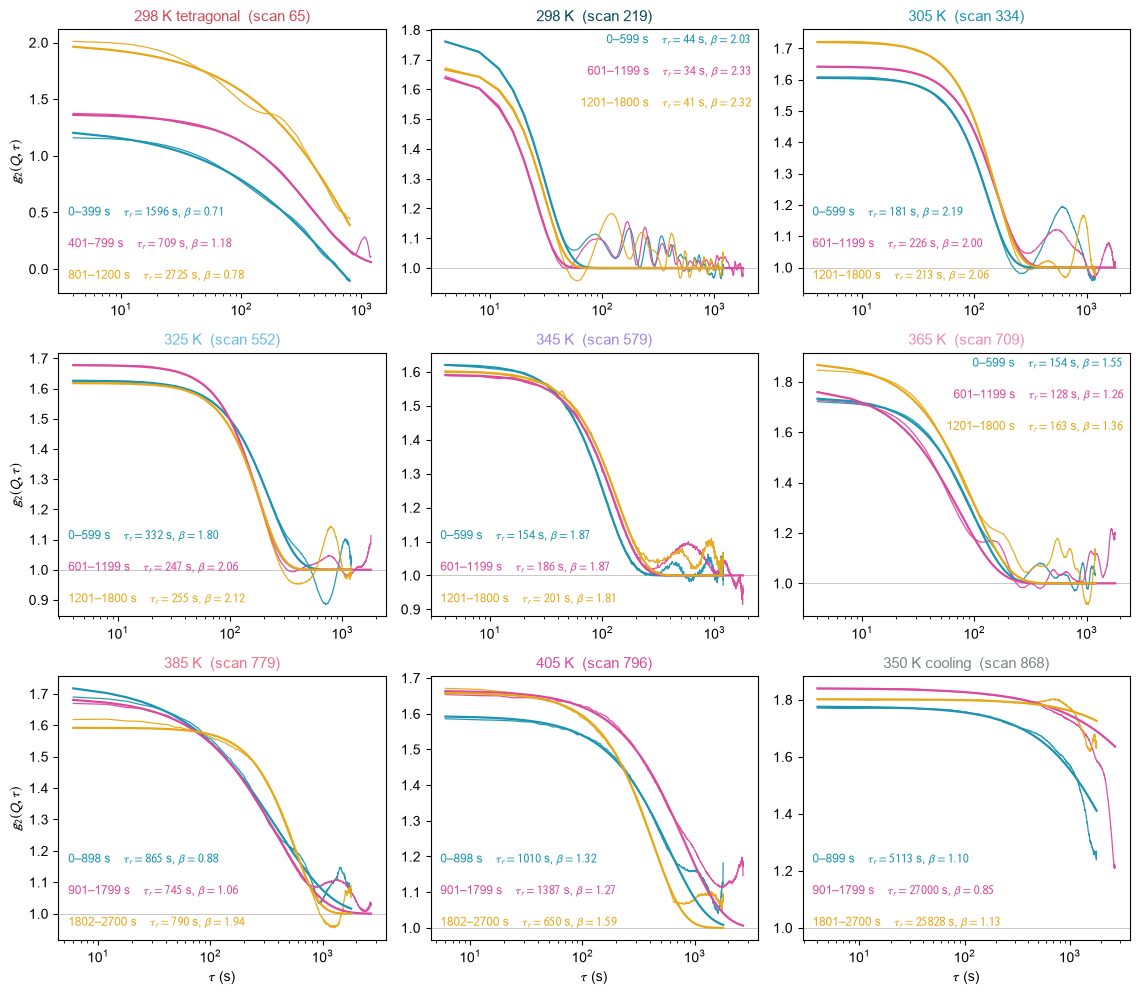

In [5]:
n_scan = len(results)
n_col = 3
n_row = int(np.ceil(n_scan / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(11.5, 3.35 * n_row), sharex=False)
axes = np.atleast_1d(axes).ravel()
block_colors = ["#1c94b0", "#da499d", "#e6a817"]

for panel, (ax, s) in enumerate(zip(axes, results)):
    last_row = panel // n_col == n_row - 1
    lower_left = last_row or s["scan"] in (65, 334, 552, 579)
    if len(s["blocks"][0]["popt"]) == 3:
        ax.axhline(1.0, color="0.75", lw=0.6, zorder=1)
    n_b = len(s["blocks"])
    for k, b in enumerate(s["blocks"]):
        color = block_colors[k % len(block_colors)]
        finite = (b["tau"] > 0) & np.isfinite(b["g2"])
        tau = b["tau"][finite]
        g2 = b["g2"][finite]
        ax.semilogx(tau, g2, "-", color=color, lw=0.9, alpha=0.95, zorder=2)
        ax.semilogx(tau, block_curve(tau, b["popt"]), "-", color=color, lw=1.6, zorder=3)
        label = rf"{b['t_lo']:.0f}–{b['t_hi']:.0f} s    $\tau_r={b['tau_r']:.0f}$ s, $\beta={b['beta']:.2f}$"
        if lower_left:
            ax.text(
                0.03, 0.04 + (n_b - 1 - k) * 0.12,
                label,
                transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, color=color,
            )
        else:
            ax.text(
                0.98, 0.98 - k * 0.12,
                label,
                transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=color,
            )
    ax.set_title(
        f"{s['label']}  (scan {s['scan']})",
        fontsize=11,
        color=SCAN_COLOR[s["scan"]],
    )
    if last_row:
        ax.set_xlabel(r"$\tau$ (s)")
    if panel % n_col == 0:
        ax.set_ylabel(r"$g_2(\boldsymbol{Q},\tau)$")

for ax in axes[n_scan:]:
    ax.axis("off")

fig.tight_layout()
fit_path = figure_path / f"tau_beta_block_fits_n{N_BLOCKS}.pdf"
fig.savefig(fit_path, dpi=200, bbox_inches="tight")
print(f"wrote {fit_path}")
plt.show()


wrote ../figures/tau_beta_errors_n3.pdf


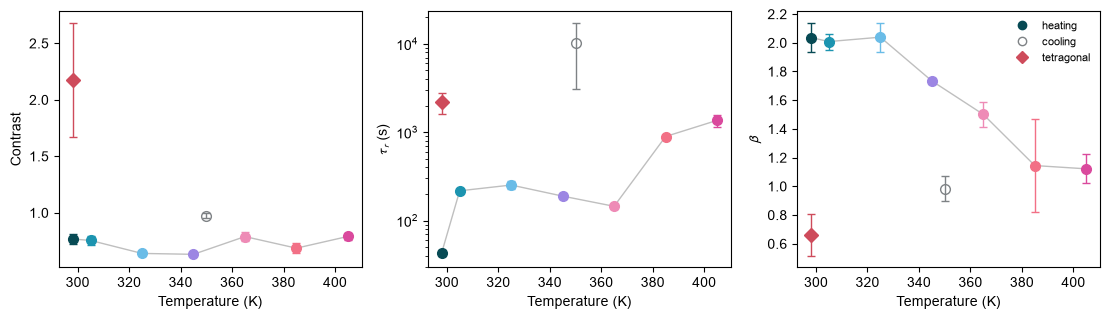

In [6]:
def ordered(scan_list):
    return [s for s in results if s["scan"] in scan_list]


heating = ordered(HEATING_SCANS)
cooling = ordered([868])
tetragonal = ordered([65])

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.3))

series = [
    (heating, True, "o", 1.0, "BM-cubic, heating"),
    (cooling, False, "o", 1.0, "BM-cubic, cooling"),
    (tetragonal, False, "D", 1.0, "tetragonal"),
]

for ax, key, sem_key, ylabel in (
    (axes[0], "contrast", "contrast_sem", "Contrast"),
    (axes[1], "tau_r", "tau_r_sem", r"$\tau_r$ (s)"),
    (axes[2], "beta", "beta_sem", r"$\beta$"),
):
    for rows, connect, marker, alpha, label in series:
        if not rows:
            continue
        T = np.array([r["T"] for r in rows])
        y = np.array([r[key] for r in rows])
        yerr = np.array([r[sem_key] for r in rows])
        colors = [SCAN_COLOR[r["scan"]] for r in rows]
        if connect:
            order = np.argsort(T)
            ax.plot(T[order], y[order], color="0.75", lw=1.0, zorder=1)
        for Ti, yi, ye, c in zip(T, y, yerr, colors):
            ax.errorbar(
                Ti, yi, yerr=ye,
                fmt=marker, color=c, ms=7, lw=1.0, capsize=3,
                markerfacecolor=("none" if rows is cooling else c),
                markeredgecolor=c,
                zorder=2,
            )
    ax.set_xlabel("Temperature (K)")
    ax.set_ylabel(ylabel)
axes[1].set_yscale("log")

axes[2].legend(
    handles=[
        plt.Line2D([0], [0], marker="o", color="#074a54", lw=0, label="heating"),
        plt.Line2D([0], [0], marker="o", color="#7e8285", lw=0, markerfacecolor="none", label="cooling"),
        plt.Line2D([0], [0], marker="D", color="#ce4b5b", lw=0, label="tetragonal"),
    ],
    frameon=False,
    fontsize=8,
)

fig.tight_layout()
summary_path = figure_path / f"tau_beta_errors_n{N_BLOCKS}.pdf"
fig.savefig(summary_path, dpi=300, bbox_inches="tight")
print(f"wrote {summary_path}")
plt.show()


wrote ../figures/error_blocks_scan219.pdf
  0–599 s   tau_r=43.97 s   beta=2.035
  601–1199 s   tau_r=34.12 s   beta=2.335
  1201–1800 s   tau_r=40.91 s   beta=2.320


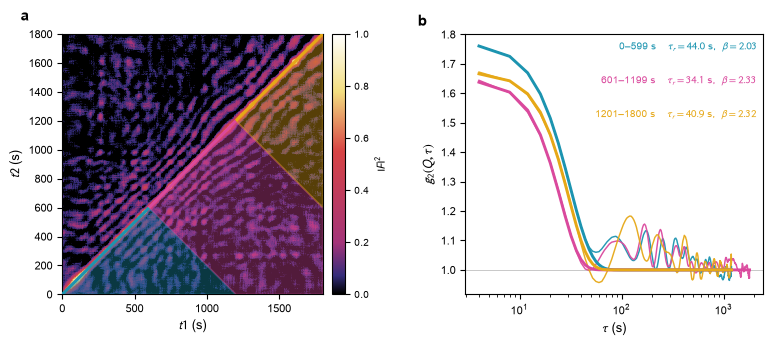

In [7]:
### Supplemental figure: how the scan 219 errors are estimated

DEMO_SCAN = 219
BLOCK_COLORS = ["#1c94b0", "#da499d", "#e6a817"]  # early, middle, late

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon

nps_custom = LinearSegmentedColormap.from_list(
    "nps_custom",
    [
        (0.00, "#000000"),
        (0.07, "#342c7a"),
        (0.20, "#a43479"),
        (0.55, "#d74444"),
        (0.78, "#f3de80"),
        (1.00, "#ffffff"),
    ],
    N=256,
)

demo = analyze_scan(DEMO_SCAN)
C, extent, _ = load_ttc(DEMO_SCAN)
t_min = float(extent[2])
t_max = float(extent[1])


def band_polygon(lo, hi, t0, t1):
    """Age band lo–hi on the t2 >= t1 side of the two-time map. Coordinates are (t2, t1)."""
    def tip(t):
        s = max(min(t - t0, t1 - t), 0.0)
        return (t + s, t - s)

    def hits_t1_edge(t):
        return (t - t0) <= (t1 - t)

    pts = [(lo, lo), (hi, hi), tip(hi)]
    if hits_t1_edge(lo) != hits_t1_edge(hi):
        pts.append((t1, t0))
    pts.append(tip(lo))
    return pts


fig, axes = plt.subplots(
    1, 2, figsize=(7.6, 3.35), layout="constrained", gridspec_kw={"wspace": 0.08}
)

ax = axes[0]
im = ax.imshow(
    C, cmap=nps_custom, origin="lower", extent=extent, vmin=0, vmax=1, interpolation="nearest"
)
for b, color in zip(demo["blocks"], BLOCK_COLORS):
    poly = band_polygon(b["t_lo"], b["t_hi"], t_min, t_max)
    ax.add_patch(
        Polygon(
            poly, closed=True, facecolor=color, edgecolor=color,
            alpha=0.38, lw=1.1, zorder=3,
        )
    )
    ax.plot([b["t_lo"], b["t_hi"]], [b["t_lo"], b["t_hi"]], color=color, lw=2.2, solid_capstyle="butt", zorder=4)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
ax.set_aspect("equal")
ax.set_xlabel(r"$t1$ (s)", fontsize=9)
ax.set_ylabel(r"$t2$ (s)", fontsize=9)
ax.tick_params(labelsize=8)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.ax.tick_params(labelsize=7)
cbar.set_label(r"$|F|^2$", fontsize=8)
ax.text(-0.16, 1.04, "a", transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")

ax = axes[1]
for i, (b, color) in enumerate(zip(demo["blocks"], BLOCK_COLORS)):
    finite = (b["tau"] > 0) & np.isfinite(b["g2"])
    tau = b["tau"][finite]
    g2 = b["g2"][finite]
    ax.semilogx(tau, g2, "-", color=color, lw=1.05, alpha=0.95, zorder=2)
    ax.semilogx(tau, block_curve(tau, b["popt"]), "-", color=color, lw=2.1, zorder=3)
    ax.text(
        0.98, 0.97 - i * 0.13,
        rf"{b['t_lo']:.0f}–{b['t_hi']:.0f} s    $\tau_r = {b['tau_r']:.1f}$ s,  $\beta = {b['beta']:.2f}$",
        transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=color,
    )
ax.axhline(1.0, color="0.75", lw=0.6, zorder=1)
ax.set_xlabel(r"$\tau$ (s)", fontsize=9)
ax.set_ylabel(r"$g_2(\boldsymbol{Q},\tau)$", fontsize=9)
ax.tick_params(labelsize=8)
ax.text(-0.16, 1.02, "b", transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")

out = figure_path / "error_blocks_scan219.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"wrote {out}")
for b in demo["blocks"]:
    print(f"  {b['t_lo']:.0f}–{b['t_hi']:.0f} s   tau_r={b['tau_r']:.2f} s   beta={b['beta']:.3f}")
plt.show()


scan 868 last segment 2162–2700 s left out of beta and contrast (tau_r=27000 s, beta=1.014)
  scan label                  contrast      err      tau_r        err     beta      err n_beta
----------------------------------------------------------------------------------------------
    65 298 K tetragonal          2.175    0.362    2190.70    1087.81    0.664    0.158      5
    0–238 s  tau_r=2041.3 s  beta=0.647
    240–479 s  tau_r=1050.2 s  beta=0.890
    481–719 s  tau_r=555.6 s  beta=1.453
    721–960 s  tau_r=2642.2 s  beta=0.892
    962–1200 s  tau_r=6695.2 s  beta=0.542
   219 298 K                     0.768    0.025      43.10       2.91    2.037    0.097      5
    0–358 s  tau_r=47.6 s  beta=2.003
    360–719 s  tau_r=36.4 s  beta=2.183
    721–1079 s  tau_r=30.7 s  beta=2.597
    1081–1440 s  tau_r=42.0 s  beta=2.272
    1442–1800 s  tau_r=42.9 s  beta=2.305
   334 305 K                     0.755    0.032     217.01      14.87    2.008    0.047      5
    0–358 s  tau_r=209

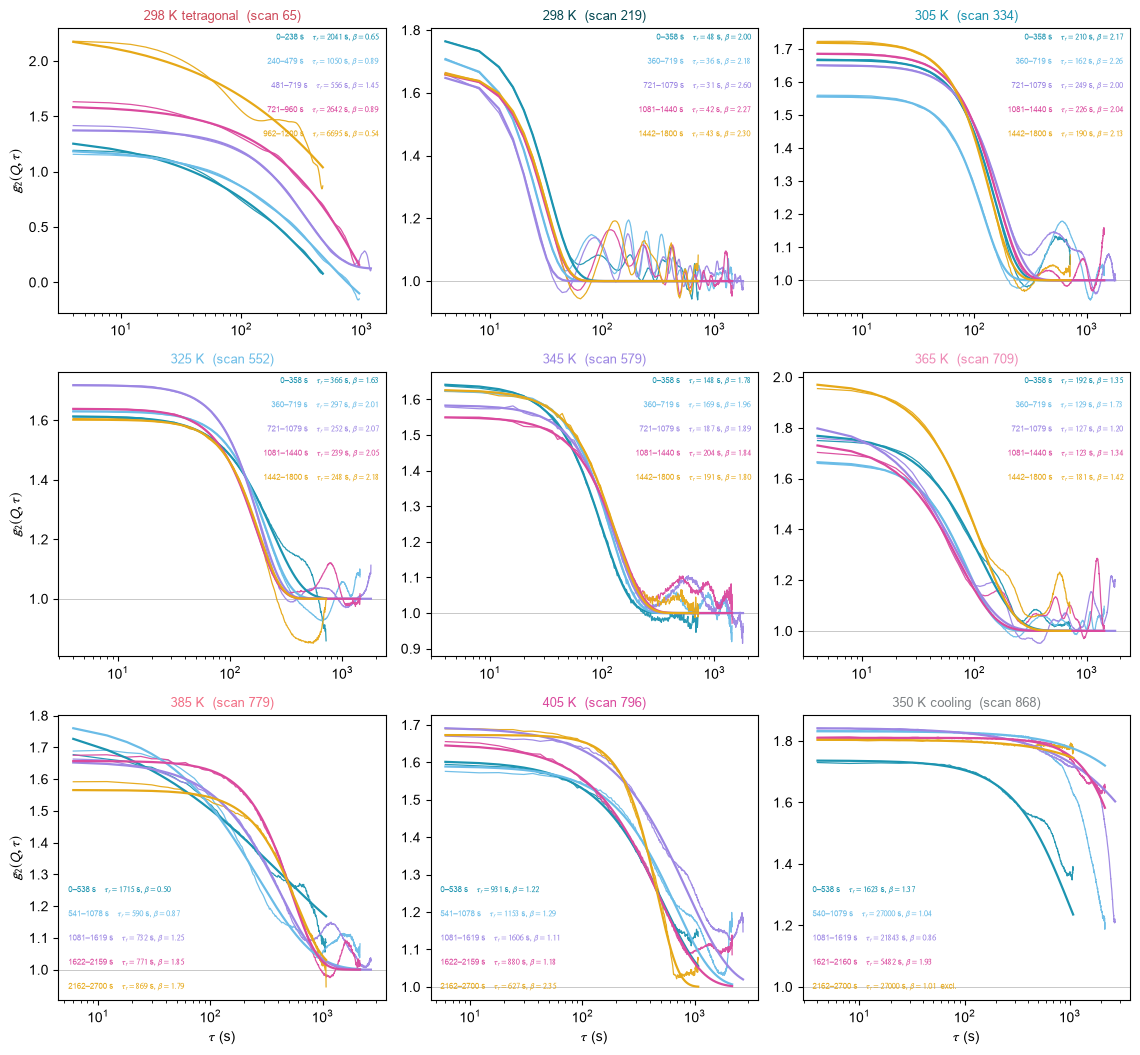

wrote ../figures/tau_beta_errors_n5.pdf


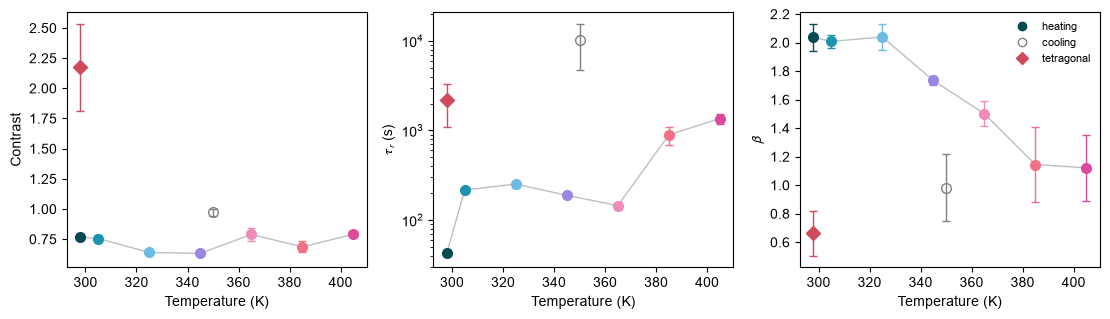

wrote ../figures/error_blocks_scan219_n5.pdf


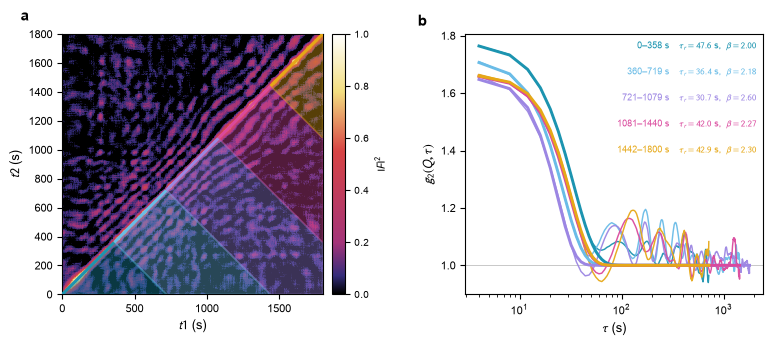

In [8]:
# Five segments. Same fits and cuts as above. Files are named n5 so the
# three-segment figures and table are left in place.
# Scan 868's last segment is the flat late-time block excluded before:
# it stays in the tau_r error and out of the beta and contrast errors.

N5 = 5
BLOCK_COLORS_5 = ["#1c94b0", "#6abce7", "#9c86e3", "#da499d", "#e6a817"]

results5 = [analyze_scan(scan, n_blocks=N5) for scan in SCANS]

for s in results5:
    if s["scan"] != 868:
        continue
    problem = s["blocks"][-1]
    kept = s["blocks"][:-1]
    problem["excluded"] = True
    beta_sem, n_beta = sample_sem([b["beta"] for b in kept])
    amp = np.array([b["A"] for b in kept], dtype=float)
    amp_sem, n_amp = sample_sem(amp)
    s["beta_sem"] = beta_sem
    s["n_beta"] = n_beta
    s["n_contrast"] = n_amp
    s["contrast_sem"] = s["contrast"] * (amp_sem / float(np.mean(amp)))
    print(
        f"scan 868 last segment {problem['t_lo']:.0f}–{problem['t_hi']:.0f} s "
        f"left out of beta and contrast "
        f"(tau_r={problem['tau_r']:.0f} s, beta={problem['beta']:.3f})"
    )

header = (
    f"{'scan':>6} {'label':<20} {'contrast':>10} {'err':>8} "
    f"{'tau_r':>10} {'err':>10} {'beta':>8} {'err':>8} {'n_beta':>6}"
)
print(header)
print("-" * len(header))
for s in results5:
    print(
        f"{s['scan']:>6} {s['label']:<20} {s['contrast']:10.3f} {s['contrast_sem']:8.3f} "
        f"{s['tau_r']:10.2f} {s['tau_r_sem']:10.2f} {s['beta']:8.3f} {s['beta_sem']:8.3f} "
        f"{s['n_beta']:6d}"
    )
    for b in s["blocks"]:
        note = "  excluded from beta, contrast" if b.get("excluded") else ""
        print(
            f"    {b['t_lo']:.0f}–{b['t_hi']:.0f} s  "
            f"tau_r={b['tau_r']:.1f} s  beta={b['beta']:.3f}{note}"
        )

table_path = figure_path / "tau_beta_errors_n5.csv"
with open(table_path, "w") as f:
    f.write(
        "scan,T_K,label,duration_s,window_s,block_tau_max_s,n_blocks,"
        "contrast,contrast_err,n_contrast,"
        "tau_r_full_s,tau_r_err_s,"
        "beta_full,beta_err,n_beta\n"
    )
    for s in results5:
        f.write(
            f"{s['scan']},{s['T']:.0f},{s['label']},{s['duration']:.4f},{s['window']:.4f},"
            f"{s['tau_max']:.4f},{s['n_blocks']},{s['contrast']:.6f},{s['contrast_sem']:.6f},"
            f"{s['n_contrast']},{s['tau_r']:.6f},{s['tau_r_sem']:.6f},"
            f"{s['beta']:.6f},{s['beta_sem']:.6f},{s['n_beta']}\n"
        )
print(f"wrote {table_path}")

n_scan = len(results5)
n_col = 3
n_row = int(np.ceil(n_scan / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(11.5, 3.55 * n_row), sharex=False)
axes = np.atleast_1d(axes).ravel()
for panel, (ax, s) in enumerate(zip(axes, results5)):
    last_row = panel // n_col == n_row - 1
    if len(s["blocks"][0]["popt"]) == 3:
        ax.axhline(1.0, color="0.75", lw=0.6, zorder=1)
    n_b = len(s["blocks"])
    for k, b in enumerate(s["blocks"]):
        color = BLOCK_COLORS_5[k % len(BLOCK_COLORS_5)]
        finite = (b["tau"] > 0) & np.isfinite(b["g2"])
        tau = b["tau"][finite]
        g2 = b["g2"][finite]
        ax.semilogx(tau, g2, "-", color=color, lw=0.9, alpha=0.95, zorder=2)
        ax.semilogx(tau, block_curve(tau, b["popt"]), "-", color=color, lw=1.6, zorder=3)
        label = rf"{b['t_lo']:.0f}–{b['t_hi']:.0f} s    $\tau_r={b['tau_r']:.0f}$ s, $\beta={b['beta']:.2f}$"
        if b.get("excluded"):
            label += "  excl."
        if last_row:
            ax.text(
                0.03, 0.03 + (n_b - 1 - k) * 0.085,
                label,
                transform=ax.transAxes, ha="left", va="bottom", fontsize=5.6, color=color,
            )
        else:
            ax.text(
                0.98, 0.98 - k * 0.085,
                label,
                transform=ax.transAxes, ha="right", va="top", fontsize=5.6, color=color,
            )
    ax.set_title(
        f"{s['label']}  (scan {s['scan']})",
        fontsize=9,
        color=SCAN_COLOR[s["scan"]],
    )
    if last_row:
        ax.set_xlabel(r"$\tau$ (s)")
    if panel % n_col == 0:
        ax.set_ylabel(r"$g_2(\boldsymbol{Q},\tau)$")
for ax in axes[n_scan:]:
    ax.axis("off")
fig.tight_layout()
fit_path = figure_path / "tau_beta_block_fits_n5.pdf"
fig.savefig(fit_path, dpi=200, bbox_inches="tight")
print(f"wrote {fit_path}")
plt.show()

def ordered5(scan_list):
    return [s for s in results5 if s["scan"] in scan_list]

heating = ordered5(HEATING_SCANS)
cooling = ordered5([868])
tetragonal = ordered5([65])
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.3))
series = [
    (heating, True, "o", "BM-cubic, heating"),
    (cooling, False, "o", "BM-cubic, cooling"),
    (tetragonal, False, "D", "tetragonal"),
]
for ax, key, sem_key, ylabel in (
    (axes[0], "contrast", "contrast_sem", "Contrast"),
    (axes[1], "tau_r", "tau_r_sem", r"$\tau_r$ (s)"),
    (axes[2], "beta", "beta_sem", r"$\beta$"),
):
    for rows, connect, marker, label in series:
        T = np.array([r["T"] for r in rows])
        y = np.array([r[key] for r in rows])
        yerr = np.array([r[sem_key] for r in rows])
        colors = [SCAN_COLOR[r["scan"]] for r in rows]
        if connect:
            order = np.argsort(T)
            ax.plot(T[order], y[order], color="0.75", lw=1.0, zorder=1)
        for Ti, yi, ye, c in zip(T, y, yerr, colors):
            ax.errorbar(
                Ti, yi, yerr=ye,
                fmt=marker, color=c, ms=7, lw=1.0, capsize=3,
                markerfacecolor=("none" if rows is cooling else c),
                markeredgecolor=c,
                zorder=2,
            )
    ax.set_xlabel("Temperature (K)")
    ax.set_ylabel(ylabel)
axes[1].set_yscale("log")
axes[2].legend(
    handles=[
        plt.Line2D([0], [0], marker="o", color="#074a54", lw=0, label="heating"),
        plt.Line2D([0], [0], marker="o", color="#7e8285", lw=0, markerfacecolor="none", label="cooling"),
        plt.Line2D([0], [0], marker="D", color="#ce4b5b", lw=0, label="tetragonal"),
    ],
    frameon=False,
    fontsize=8,
)
fig.tight_layout()
summary_path = figure_path / "tau_beta_errors_n5.pdf"
fig.savefig(summary_path, dpi=300, bbox_inches="tight")
print(f"wrote {summary_path}")
plt.show()

demo = next(s for s in results5 if s["scan"] == 219)
C, extent, _ = load_ttc(219)
t_min = float(extent[2])
t_max = float(extent[1])
fig, axes = plt.subplots(
    1, 2, figsize=(7.6, 3.35), layout="constrained", gridspec_kw={"wspace": 0.08}
)
ax = axes[0]
im = ax.imshow(
    C, cmap=nps_custom, origin="lower", extent=extent, vmin=0, vmax=1, interpolation="nearest"
)
for b, color in zip(demo["blocks"], BLOCK_COLORS_5):
    poly = band_polygon(b["t_lo"], b["t_hi"], t_min, t_max)
    ax.add_patch(
        Polygon(
            poly, closed=True, facecolor=color, edgecolor=color,
            alpha=0.38, lw=1.1, zorder=3,
        )
    )
    ax.plot([b["t_lo"], b["t_hi"]], [b["t_lo"], b["t_hi"]], color=color, lw=2.2, solid_capstyle="butt", zorder=4)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
ax.set_aspect("equal")
ax.set_xlabel(r"$t1$ (s)", fontsize=9)
ax.set_ylabel(r"$t2$ (s)", fontsize=9)
ax.tick_params(labelsize=8)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.ax.tick_params(labelsize=7)
cbar.set_label(r"$|F|^2$", fontsize=8)
ax.text(-0.16, 1.04, "a", transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")
ax = axes[1]
for i, (b, color) in enumerate(zip(demo["blocks"], BLOCK_COLORS_5)):
    finite = (b["tau"] > 0) & np.isfinite(b["g2"])
    tau = b["tau"][finite]
    g2 = b["g2"][finite]
    ax.semilogx(tau, g2, "-", color=color, lw=1.05, alpha=0.95, zorder=2)
    ax.semilogx(tau, block_curve(tau, b["popt"]), "-", color=color, lw=2.1, zorder=3)
    ax.text(
        0.98, 0.97 - i * 0.10,
        rf"{b['t_lo']:.0f}–{b['t_hi']:.0f} s    $\tau_r = {b['tau_r']:.1f}$ s,  $\beta = {b['beta']:.2f}$",
        transform=ax.transAxes, ha="right", va="top", fontsize=6.5, color=color,
    )
ax.axhline(1.0, color="0.75", lw=0.6, zorder=1)
ax.set_xlabel(r"$\tau$ (s)", fontsize=9)
ax.set_ylabel(r"$g_2(\boldsymbol{Q},\tau)$", fontsize=9)
ax.tick_params(labelsize=8)
ax.text(-0.16, 1.02, "b", transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")
out = figure_path / "error_blocks_scan219_n5.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"wrote {out}")
plt.show()
